In [ ]:
import os
import calendar
import numpy as np
import xarray as xr

# =========================================================
# Input files
# =========================================================
mask_file = "/work/home/H.extreme/IPCS_extreme/Plot_main_text_Figure/outcomes/valid_event_days_1981_2023_new.nc"
et_cli_file = "/work/home/H.extreme/IPCS_extreme/share/thirstwave_detection/tx01_cli_julianday.nc"
et_90_file = "/work/home/H.extreme/IPCS_extreme/share/thirstwave_detection/tx01_90_c.nc"
era5_path = "/work5/ERA5_daily_landgrid_only/global/compressed_sfc_fc_daily_198001.nc4"
data_dir = "/work/home/H.extreme/IPCS_extreme/share/daily_ETos/ETos_term"

A_dir = "/work7/IPCS_extreme/share/daily_ETos/A_term"
B_dir = "/work7/IPCS_extreme/share/daily_ETos/B_term"
C_dir = "/work7/IPCS_extreme/share/daily_ETos/C_term"

out_file = "thirstwave_metrics_growing_season.nc"

years = np.arange(1981, 2024)
ny = len(years)

# =========================================================
# Helper functions
# =========================================================
def get_growing_month_mask(lat_arr, month):
    """
    Growing season definition:
    NH: Apr-Oct
    SH: Oct-Apr
    """
    out = np.zeros(lat_arr.shape, dtype=bool)

    nh = lat_arr >= 0
    sh = lat_arr < 0

    out[nh] = (4 <= month <= 10)
    out[sh] = (month >= 10) | (month <= 4)

    return out


def remove_feb29_if_needed(data, year, month):
    """
    Remove Feb 29 so monthly data match the 365-day calendar.
    Assumes time is the first dimension.
    """
    if month == 2 and calendar.isleap(year):
        if data.shape[0] == 29:
            data = np.delete(data, 28, axis=0)  # remove Feb 29
        elif data.shape[0] != 28:
            raise ValueError(
                f"Unexpected number of days in {year}-{month:02d}: {data.shape[0]}"
            )
    return data


# =========================================================
# Read mask
# =========================================================
ds_mask = xr.open_dataset(mask_file)
mask = ds_mask["ETos"].values.astype(bool)   # shape: (time, lgrid)
lgrid = ds_mask["lgrid"].values
n_time, n_grid = mask.shape

# =========================================================
# Read lat/lon from ERA5 reference file
# =========================================================
ds_era5 = xr.open_dataset(era5_path)
lat_1d = ds_era5["lat"].values
lon_1d = ds_era5["lon"].values

lat_grid = lat_1d[lgrid]
lon_grid = lon_1d[lgrid]

# =========================================================
# Read 365-day p90 threshold
# =========================================================
ds_cli = xr.open_dataset(et_cli_file)
ds_p90 = xr.open_dataset(et_90_file)

# Change this variable name if needed
p90_all = ds_p90["ETos"].values
cli_all = ds_cli["ETos"].values

if p90_all.shape[0] != 365:
    raise ValueError(f"Expected first dimension of p90 to be 365, got {p90_all.shape[0]}")

if p90_all.shape[1] != n_grid:
    raise ValueError(
        f"Grid mismatch: p90 has {p90_all.shape[1]} grid cells, mask has {n_grid}"
    )

# =========================================================
# Precompute growing season mask by month
# =========================================================
grow_mask_by_month = {m: get_growing_month_mask(lat_grid, m) for m in range(1, 13)}
# =========================================================
# Precompute growing season mask by month
# =========================================================
grow_mask_by_month = {
    m: get_growing_month_mask(lat_grid, m)
    for m in range(1, 13)
}

# =========================================================
# Event-based thirstwave metrics
# =========================================================
sum_event_intensity = np.zeros((ny, n_grid), dtype=np.float32)
event_count = np.zeros((ny, n_grid), dtype=np.float32)

true_days = np.zeros((ny, n_grid), dtype=np.float32)
gs_days = np.zeros((ny, n_grid), dtype=np.float32)

t_index = 0

for yi, y in enumerate(years):

    prev_last_day = np.zeros(n_grid, dtype=bool)

    current_event_sum = np.zeros(n_grid, dtype=np.float32)
    current_event_count = np.zeros(n_grid, dtype=np.float32)

    doy_index = 0

    for m in range(1, 13):

        file = f"{data_dir}/ETos_{y}{m:02d}.npy"

        if not os.path.exists(file):
            raise FileNotFoundError(f"Missing file: {file}")

        data = np.load(file).astype(np.float32)

        data = remove_feb29_if_needed(data, y, m)

        nday = data.shape[0]

        mask_month_all = mask[t_index:t_index + nday, :]

        p90 = p90_all[doy_index:doy_index + nday, :]

        grow_mask_1d = grow_mask_by_month[m]

        mask_month = mask_month_all & grow_mask_1d[None, :]

        anomaly = data - p90

        true_days[yi, :] += np.sum(mask_month, axis=0)

        gs_days[yi, :] += (
            nday * grow_mask_1d.astype(np.float32)
        )

        for di in range(nday):

            today = mask_month[di, :]

            anom_today = anomaly[di, :]

            start = today & (~prev_last_day)

            end = (~today) & prev_last_day

            # finalize ended events
            valid_end = end & (current_event_count > 0)

            sum_event_intensity[yi, valid_end] += (
                current_event_sum[valid_end]
                / current_event_count[valid_end]
            )

            event_count[yi, valid_end] += 1

            current_event_sum[valid_end] = 0
            current_event_count[valid_end] = 0

            # initialize new events
            current_event_sum[start] = 0
            current_event_count[start] = 0

            # accumulate ongoing events
            current_event_sum[today] += anom_today[today]
            current_event_count[today] += 1

            prev_last_day = today

        t_index += nday
        doy_index += nday

    # finalize events continuing to last day
    valid_end = prev_last_day & (current_event_count > 0)

    sum_event_intensity[yi, valid_end] += (
        current_event_sum[valid_end]
        / current_event_count[valid_end]
    )

    event_count[yi, valid_end] += 1

# =========================================================
# Final event-based metrics
# =========================================================
intensity = sum_event_intensity / event_count
intensity[event_count == 0] = np.nan

mean_duration = true_days / event_count
mean_duration[event_count == 0] = np.nan

event_freq_100d = event_count / gs_days * 100.0
event_freq_100d[gs_days == 0] = np.nan

day_fraction = true_days / gs_days
day_fraction[gs_days == 0] = np.nan

# =========================================================
# Step 1. Compute daily climatology of A/C and B/C
# Baseline: 1981–2000
# =========================================================
clim_years = np.arange(1981, 2001)

sum_AoverC_cli = np.zeros((365, n_grid), dtype=np.float64)
sum_BoverC_cli = np.zeros((365, n_grid), dtype=np.float64)

cnt_AoverC_cli = np.zeros((365, n_grid), dtype=np.float64)
cnt_BoverC_cli = np.zeros((365, n_grid), dtype=np.float64)

for y in clim_years:

    doy_index = 0

    for m in range(1, 13):

        A_file = f"{A_dir}/A_{y}{m:02d}.npy"
        B_file = f"{B_dir}/B_{y}{m:02d}.npy"
        C_file = f"{C_dir}/C_{y}{m:02d}.nc"

        A = np.load(A_file).astype(np.float32)
        B = np.load(B_file).astype(np.float32)

        ds_C = xr.open_dataset(C_file)

        c_varname = (
            "C" if "C" in ds_C
            else list(ds_C.data_vars)[0]
        )

        C = ds_C[c_varname].values.astype(np.float32)

        ds_C.close()

        if A.shape[0] == n_grid:
            A = A.T

        if B.shape[0] == n_grid:
            B = B.T

        if C.shape[0] == n_grid:
            C = C.T

        A = remove_feb29_if_needed(A, y, m)
        B = remove_feb29_if_needed(B, y, m)
        C = remove_feb29_if_needed(C, y, m)

        nday = A.shape[0]

        with np.errstate(divide="ignore", invalid="ignore"):

            AoverC = A / C
            BoverC = B / C

        valid_A = np.isfinite(AoverC)
        valid_B = np.isfinite(BoverC)

        sl = slice(doy_index, doy_index + nday)

        sum_AoverC_cli[sl, :] += np.where(
            valid_A, AoverC, 0.0
        )

        sum_BoverC_cli[sl, :] += np.where(
            valid_B, BoverC, 0.0
        )

        cnt_AoverC_cli[sl, :] += valid_A
        cnt_BoverC_cli[sl, :] += valid_B

        doy_index += nday

AoverC_cli_all = sum_AoverC_cli / cnt_AoverC_cli
BoverC_cli_all = sum_BoverC_cli / cnt_BoverC_cli

AoverC_cli_all[cnt_AoverC_cli == 0] = np.nan
BoverC_cli_all[cnt_BoverC_cli == 0] = np.nan

# =========================================================
# Event-based radiative contribution fraction
# =========================================================
sum_event_rad_frac = np.zeros((ny, n_grid), dtype=np.float32)

count_event_rad_frac = np.zeros((ny, n_grid), dtype=np.float32)

t_index = 0

for yi, y in enumerate(years):

    prev_last_day = np.zeros(n_grid, dtype=bool)

    current_rad_sum = np.zeros(n_grid, dtype=np.float32)
    current_rad_count = np.zeros(n_grid, dtype=np.float32)

    doy_index = 0

    for m in range(1, 13):

        A_file = f"{A_dir}/A_{y}{m:02d}.npy"
        B_file = f"{B_dir}/B_{y}{m:02d}.npy"
        C_file = f"{C_dir}/C_{y}{m:02d}.nc"

        A = np.load(A_file).astype(np.float32)
        B = np.load(B_file).astype(np.float32)

        ds_C = xr.open_dataset(C_file)

        c_varname = (
            "C" if "C" in ds_C
            else list(ds_C.data_vars)[0]
        )

        C = ds_C[c_varname].values.astype(np.float32)

        ds_C.close()

        if A.shape[0] == n_grid:
            A = A.T

        if B.shape[0] == n_grid:
            B = B.T

        if C.shape[0] == n_grid:
            C = C.T

        A = remove_feb29_if_needed(A, y, m)
        B = remove_feb29_if_needed(B, y, m)
        C = remove_feb29_if_needed(C, y, m)

        nday = A.shape[0]

        mask_month_all = mask[t_index:t_index + nday, :]

        grow_mask_1d = grow_mask_by_month[m]

        mask_month = (
            mask_month_all &
            grow_mask_1d[None, :]
        )

        AoverC_cli = AoverC_cli_all[
            doy_index:doy_index + nday, :
        ]

        BoverC_cli = BoverC_cli_all[
            doy_index:doy_index + nday, :
        ]

        with np.errstate(divide="ignore", invalid="ignore"):

            Rad = A / C
            Adv = B / C

            dRad = Rad - AoverC_cli
            dAdv = Adv - BoverC_cli

            denom = dRad + dAdv

            rad_frac = dRad / denom

            rad_frac[denom <= 0] = np.nan
            rad_frac[~np.isfinite(rad_frac)] = np.nan

        for di in range(nday):

            today = mask_month[di, :]

            rf_today = rad_frac[di, :]

            finite_today = (
                today &
                np.isfinite(rf_today)
            )

            start = today & (~prev_last_day)

            end = (~today) & prev_last_day

            valid_end = (
                end &
                (current_rad_count > 0)
            )

            sum_event_rad_frac[yi, valid_end] += (
                current_rad_sum[valid_end]
                / current_rad_count[valid_end]
            )

            count_event_rad_frac[yi, valid_end] += 1

            current_rad_sum[valid_end] = 0
            current_rad_count[valid_end] = 0

            current_rad_sum[start] = 0
            current_rad_count[start] = 0

            current_rad_sum[finite_today] += (
                rf_today[finite_today]
            )

            current_rad_count[finite_today] += 1

            prev_last_day = today

        t_index += nday
        doy_index += nday

    valid_end = (
        prev_last_day &
        (current_rad_count > 0)
    )

    sum_event_rad_frac[yi, valid_end] += (
        current_rad_sum[valid_end]
        / current_rad_count[valid_end]
    )

    count_event_rad_frac[yi, valid_end] += 1

rad_frac_tw = np.full(
    (ny, n_grid),
    np.nan,
    dtype=np.float32
)

valid = count_event_rad_frac > 0

rad_frac_tw[valid] = (
    sum_event_rad_frac[valid]
    / count_event_rad_frac[valid]
)

# =========================================================
# Build output dataset
# =========================================================
ds_out = xr.Dataset(
    {
        "intensity": (
            ("year", "lgrid"),
            intensity
        ),

        "event_count": (
            ("year", "lgrid"),
            event_count
        ),

        "mean_duration": (
            ("year", "lgrid"),
            mean_duration
        ),

        "true_days": (
            ("year", "lgrid"),
            true_days
        ),

        "gs_days": (
            ("year", "lgrid"),
            gs_days
        ),

        "event_freq_100d": (
            ("year", "lgrid"),
            event_freq_100d
        ),

        "day_fraction": (
            ("year", "lgrid"),
            day_fraction
        ),

        "rad_frac_tw": (
            ("year", "lgrid"),
            rad_frac_tw
        ),

        "lat": (
            ("lgrid",),
            lat_grid
        ),

        "lon": (
            ("lgrid",),
            lon_grid
        ),
    },

    coords={
        "year": years,
        "lgrid": lgrid,
    }
)

# =========================================================
# Metadata
# =========================================================
ds_out["intensity"].attrs["long_name"] = (
    "mean event-based ET0 anomaly during thirstwaves in growing season"
)

ds_out["intensity"].attrs["units"] = "mm day-1"

ds_out["event_count"].attrs["units"] = "events year-1"

ds_out["mean_duration"].attrs["units"] = "days event-1"

ds_out["true_days"].attrs["units"] = "days year-1"

ds_out["event_freq_100d"].attrs["units"] = (
    "events per 100 growing-season days"
)

ds_out["rad_frac_tw"].attrs["units"] = "1"

# =========================================================
# Save
# =========================================================
ds_out.to_netcdf(out_file)

print(ds_out)

print(out_file)

/tmp/ipykernel_2680257/1405705764.py:205: RuntimeWarning: invalid value encountered in divide
  intensity = sum_event_intensity / event_count
/tmp/ipykernel_2680257/1405705764.py:208: RuntimeWarning: invalid value encountered in divide
  mean_duration = true_days / event_count


<xarray.Dataset> Size: 197MB
Dimensions:          (year: 43, lgrid: 141780)
Coordinates:
  * year             (year) int64 344B 1981 1982 1983 1984 ... 2021 2022 2023
  * lgrid            (lgrid) int64 1MB 0 1 2 3 4 ... 141776 141777 141778 141779
Data variables:
    intensity        (year, lgrid) float32 24MB 0.1822 0.1403 ... 0.2323 0.22
    event_count      (year, lgrid) float32 24MB 2.0 3.0 3.0 2.0 ... 2.0 1.0 2.0
    mean_duration    (year, lgrid) float32 24MB 3.5 3.667 3.667 ... 3.5 5.0 5.0
    true_days        (year, lgrid) float32 24MB 7.0 11.0 11.0 ... 7.0 5.0 10.0
    gs_days          (year, lgrid) float32 24MB 214.0 214.0 ... 212.0 212.0
    event_freq_100d  (year, lgrid) float32 24MB 0.9346 1.402 ... 0.4717 0.9434
    day_fraction     (year, lgrid) float32 24MB 0.03271 0.0514 ... 0.04717
    rad_frac_tw      (year, lgrid) float32 24MB -0.2079 -0.121 ... 0.4099 0.3969
    lat              (lgrid) float32 567kB 83.33 83.33 83.33 ... -55.22 -55.22
    lon              (lgrid) 

In [5]:
import matplotlib.pyplot as plt

def era5_global_weighted_mean(ds: xr.Dataset, era5_ref: xr.Dataset):
    """Computes spatial weighted mean of data variables in ds."""
    ds = ds.assign_coords(
        lat=("lgrid", era5_ref["lat"].values),
        lon=("lgrid", era5_ref["lon"].values),
    )
    weights = np.cos(np.deg2rad(ds.lat))
    ds_weighed = ds.weighted(weights)
    era5_weighted_mean = ds_weighed.mean('lgrid')
    return era5_weighted_mean


era5_path = "/work5/ERA5_daily_landgrid_only/global/compressed_sfc_fc_daily_198001.nc4"
era5 = xr.open_dataset(era5_path)

file_current = "/work/home/H.extreme/IPCS_extreme/Plot_main_text_Figure/outcomes/thirstwave_metrics_growing_season.nc"
file_new = "/work/home/H.extreme/IPCS_extreme/Plot_main_text_Figure/outcomes/thirstwave_metrics_growing_season_new.nc"

tw_features_current = xr.open_dataset(file_current)
tw_features_new = xr.open_dataset(file_new)

mean_current = era5_global_weighted_mean(tw_features_current, era5_ref=era5)
mean_new = era5_global_weighted_mean(tw_features_new, era5_ref=era5)

<>:21: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:21: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
/tmp/ipykernel_2680257/3190783702.py:21: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  ax.set_ylabel('$\Delta$ ETos$_{Rad}$')


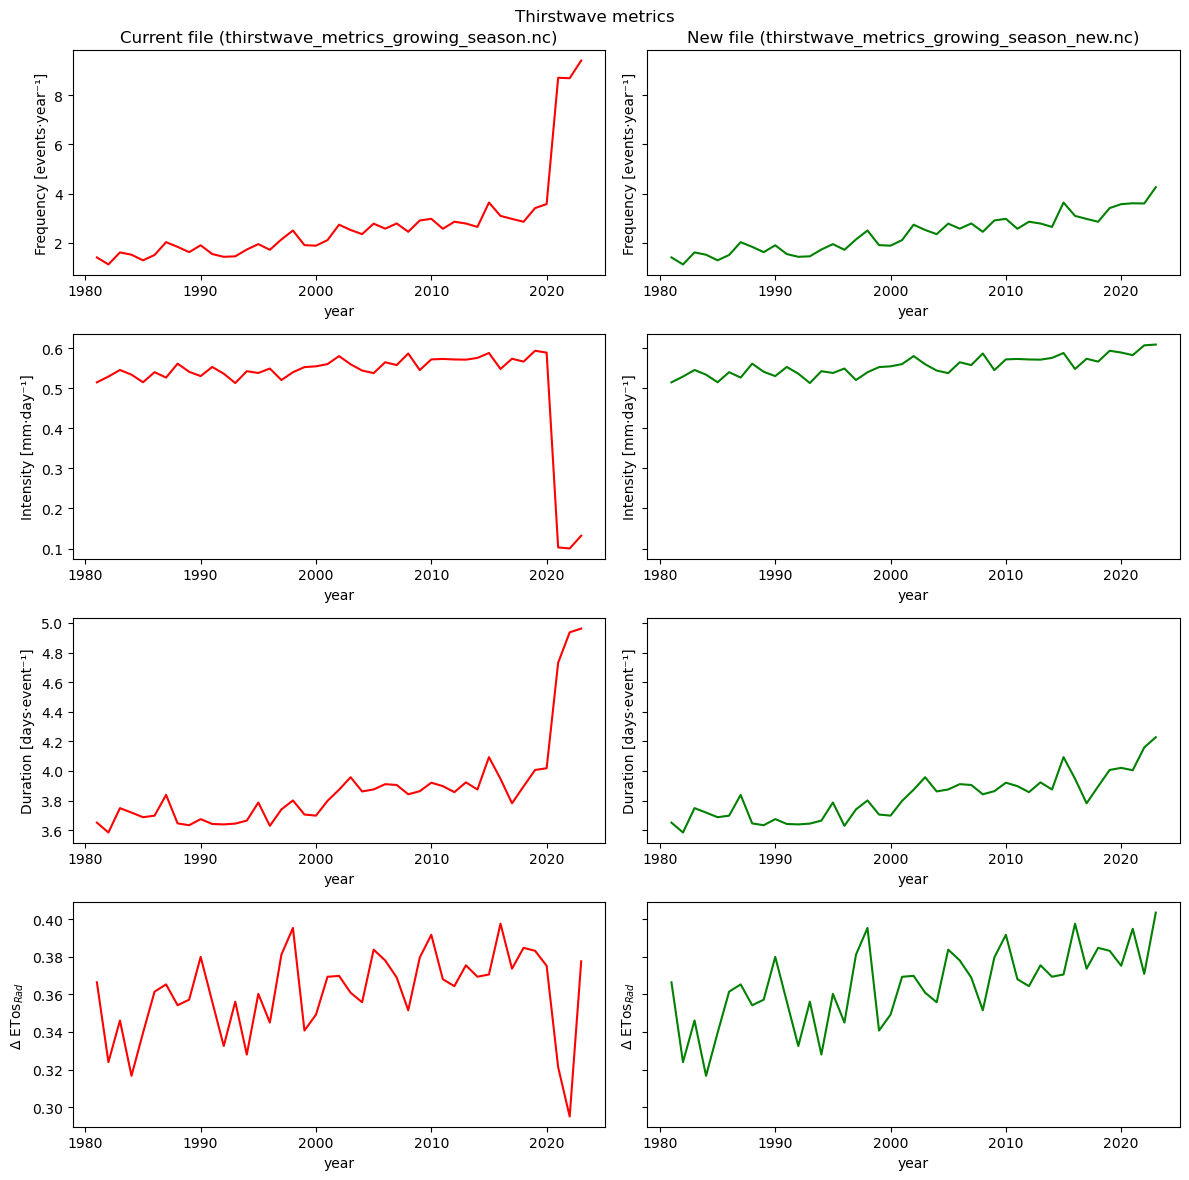

In [20]:
# Plot
fig, axes = plt.subplots(4, 2, sharey='row', figsize=(12, 12))

metrics = ['event_count', 'intensity', 'mean_duration', 'rad_frac_tw']

for i, metric in enumerate(metrics):
    mean_current[metric].plot(ax=axes[i, 0], color='red')
    mean_new[metric].plot(ax=axes[i, 1], color='green')

fig.suptitle("Thirstwave metrics")
axes[0, 0].set_title("Current file (thirstwave_metrics_growing_season.nc)")
axes[0, 1].set_title("New file (thirstwave_metrics_growing_season_new.nc)")

for ax in axes[0, :]:
    ax.set_ylabel('Frequency [events·year⁻¹]')
for ax in axes[1, :]:
    ax.set_ylabel('Intensity [mm·day⁻¹]')
for ax in axes[2, :]:
    ax.set_ylabel('Duration [days·event⁻¹]')
for ax in axes[3, :]:
    ax.set_ylabel('$\Delta$ ETos$_{Rad}$')

plt.tight_layout()